# 05 — Modelo preditivo de engajamento

**Entrada:** características conhecidas **antes** de publicar (plataforma, formato, categoria, idioma, dia/hora, seguidores, duração, hashtags, legenda, patrocínio, audiência).
**Saída:** engajamento estimado = (likes + shares + comentários) / views, com intervalo de 90%.

**Protocolo (igual para todos):**
- mesmos 5 folds de validação cruzada;
- comparação contra um **baseline** que chuta a média;
- teste pareado entre folds: o modelo só é adotado se for **significativamente melhor** que o baseline;
- R² de treino ao lado do de validação, para expor overfitting.

| Família | Modelos |
|---|---|
| Baselines | média geral, média por plataforma |
| Lineares | Ridge, Lasso, ElasticNet |
| Vizinhos | KNN (k=50) |
| Rede neural | MLP (64-32) |
| Árvores | árvore de decisão, Random Forest, Extra Trees |
| Boosting | HistGradientBoosting, XGBoost, LightGBM, CatBoost |

In [1]:
# Setup: make solution/src importable and load the posts with derived features.
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "solution" / "src").exists())
sys.path.insert(0, str(ROOT / "solution" / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from social_insights import data, top_performers as tp, clustering as cl, drivers as dr, audience as au, nlp, validation as va, plots

plots.apply_style()
pd.set_option("display.float_format", "{:.4f}".format)
df = data.load_posts(ROOT)
print(f"{len(df):,} posts")

from social_insights import engagement_model as em
from social_insights.questions import ENGAGEMENT

52,214 posts


## 1. Comparação das 14 abordagens (regressão)

In [2]:
summary, fold_mse = em.compare_models(df)
summary.style.format({"R² validação": "{:.4f}", "R² treino": "{:.4f}", "MAE": "{:.5f}", "RMSE": "{:.5f}",
                      "ganho MAE vs. baseline (%)": "{:+.3f}", "p (melhor que baseline)": "{:.3f}"})

,família,R² validação,R² treino,MAE,RMSE,ganho MAE vs. baseline (%),p (melhor que baseline),supera baseline
modelo,,,,,,,,
Média (baseline),baseline,-0.0001,0.0000,0.00388,0.00487,+0.000,1.000,False
Média por plataforma,baseline,-0.0002,0.0001,0.00388,0.00487,+0.000,0.789,False
Lasso,linear,-0.0002,0.0004,0.00388,0.00487,-0.005,0.715,False
ElasticNet,linear,-0.0004,0.0008,0.00388,0.00487,-0.017,0.821,False
CatBoost,boosting,-0.0005,0.0048,0.00388,0.00487,-0.016,0.921,False
HistGradientBoosting,boosting,-0.0007,0.0047,0.00388,0.00487,-0.028,0.992,False
Ridge,linear,-0.0009,0.0011,0.00388,0.00487,-0.051,0.936,False
Random Forest,ensemble de árvores,-0.0018,0.0926,0.00388,0.00487,-0.067,0.991,False
Extra Trees,ensemble de árvores,-0.0030,0.0926,0.00389,0.00488,-0.135,0.999,False


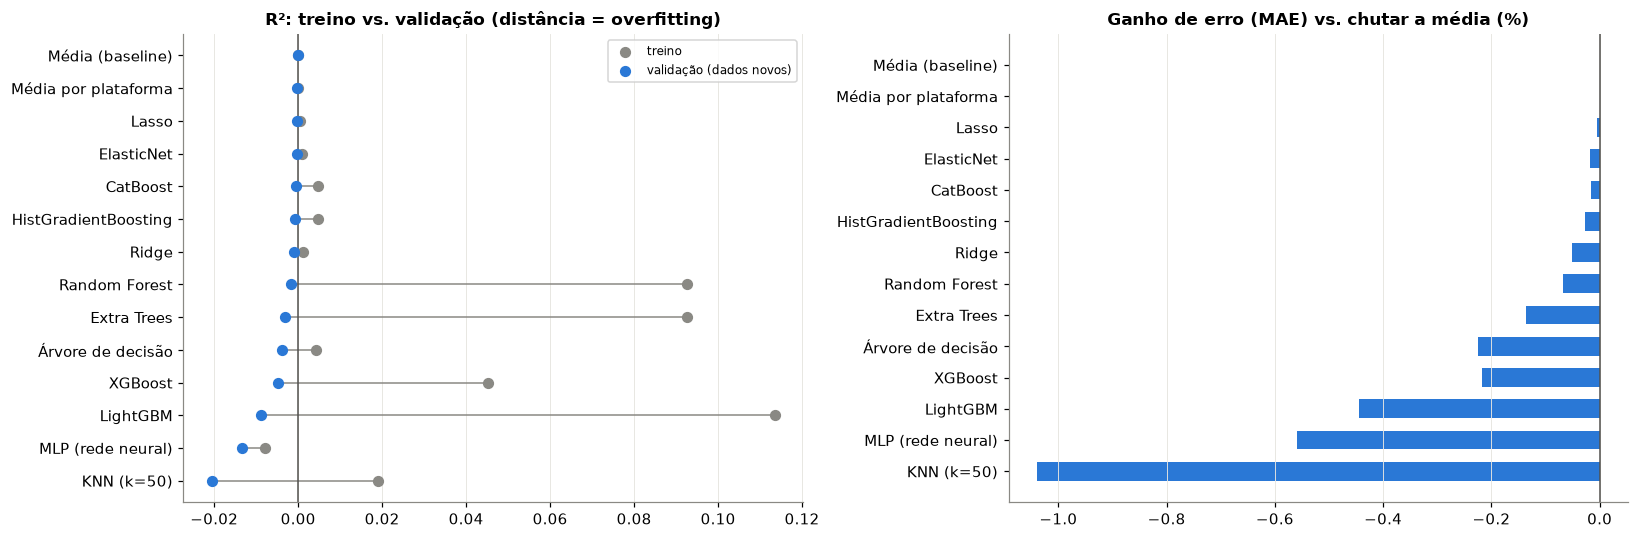

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
order = summary.sort_values("R² validação").index
y = np.arange(len(order))
axes[0].scatter(summary.loc[order, "R² treino"], y, color=plots.GRAY, s=40, label="treino", zorder=3)
axes[0].scatter(summary.loc[order, "R² validação"], y, color=plots.BLUE, s=40, label="validação (dados novos)", zorder=3)
for i, m in enumerate(order):
    axes[0].plot([summary.loc[m, "R² validação"], summary.loc[m, "R² treino"]], [i, i], color=plots.GRAY, linewidth=1)
axes[0].axvline(0, color=plots.INK, linewidth=1)
axes[0].set_yticks(y, order); axes[0].set_title("R²: treino vs. validação (distância = overfitting)"); axes[0].legend(fontsize=8)
axes[1].barh(y, summary.loc[order, "ganho MAE vs. baseline (%)"], color=plots.BLUE, height=0.6)
axes[1].axvline(0, color=plots.INK, linewidth=1)
axes[1].set_yticks(y, order); axes[1].set_title("Ganho de erro (MAE) vs. chutar a média (%)")
for ax in axes: ax.grid(axis="y", visible=False)
fig.tight_layout(); plt.show()

**Leitura:** nenhum modelo supera o baseline (todos com p ≥ 0,05; R² de validação ≤ 0).
Modelos flexíveis **decoram o treino**: Random Forest e Extra Trees chegam a R² 0,09 no treino, LightGBM 0,11 e XGBoost 0,05, e todos ficam **piores** que a média em dados novos. O KNN é o pior (−1% de MAE vs. a média).
Os lineares regularizados (Lasso/ElasticNet) empatam com a média porque zeram quase todos os coeficientes, ou seja, "aprendem" que não há sinal.

## 2. Outra formulação: classificar o post como top 10% de engajamento

In [4]:
top = tp.flag_top(df, ENGAGEMENT)
em.compare_classifiers(df, top).round(4)

,AUC média,AUC desvio
modelo,,
Regressão logística,0.5003,0.0108
HistGradientBoosting,0.4927,0.0043
XGBoost,0.4966,0.0079


**Leitura:** AUC ≈ 0,50 (cara ou coroa) nos 3 classificadores. Mudar a formulação não cria sinal.

## 3. Mais dados ajudariam? (curva de aprendizado)

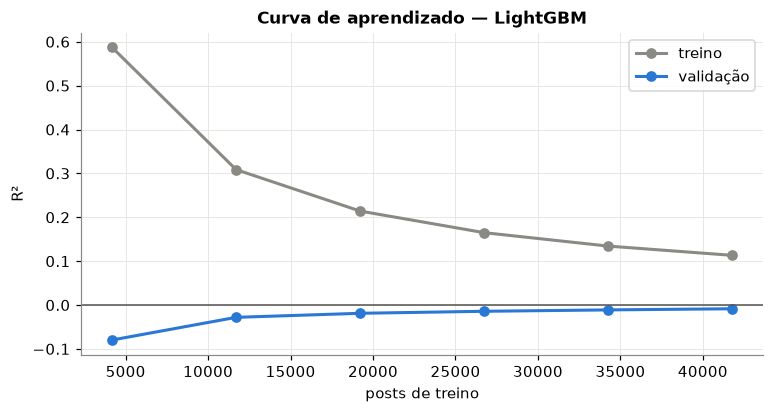

,posts de treino,R² treino,R² validação
0,4177,0.5871,-0.0798
1,11695,0.3086,-0.0281
2,19214,0.2142,-0.0189
3,26733,0.1649,-0.0143
4,34252,0.1343,-0.0111
5,41771,0.1132,-0.0085


In [5]:
lc = em.learning_curve_table(df, "LightGBM")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(lc["posts de treino"], lc["R² treino"], "o-", color=plots.GRAY, linewidth=2, label="treino")
ax.plot(lc["posts de treino"], lc["R² validação"], "o-", color=plots.BLUE, linewidth=2, label="validação")
ax.axhline(0, color=plots.INK, linewidth=1); ax.set_xlabel("posts de treino"); ax.set_ylabel("R²")
ax.set_title("Curva de aprendizado — LightGBM"); ax.legend(); plt.show()
lc.round(4)

**Leitura:** com mais dados, o R² de treino **cai** de 0,59 para 0,11 (fica mais difícil decorar) e o de validação sobe de −0,08 para −0,01, **sem nunca passar de 0**.
Isso é o padrão de "não há sinal a aprender", e não de falta de dados. Coletar mais posts com as mesmas colunas não resolveria.

## 4. Teste de sensibilidade: quais modelos achariam um sinal real?
Plantamos dois tipos de efeito de **+5% nos likes** e repetimos a comparação:
- **A. Segmento** (aditivo): TikTok × vídeo × tech (~2% dos posts).
- **B. Não linear** (interação numérica): duração entre 100 e 200 **e** postado entre 18h e 22h (~4% dos posts).

In [6]:
SUBSET = ["Média (baseline)", "Ridge", "KNN (k=50)", "MLP (rede neural)", "Árvore de decisão", "Random Forest", "LightGBM", "CatBoost"]
models = {k: v for k, v in em.candidate_models().items() if k in SUBSET}
scenarios = {
    "A. segmento (TikTok × vídeo × tech)": va.demo_segment(df),
    "B. não linear (duração 100–200 & 18–22h)": df.content_length.between(100, 200) & df.hour.between(18, 21),
}
sensitivity = {}
for name, mask in scenarios.items():
    injected = va.inject_engagement_uplift(df, mask, uplift=0.05)
    s, _ = em.compare_models(injected, models=models)
    sensitivity[name] = s[["R² validação", "ganho MAE vs. baseline (%)", "p (melhor que baseline)", "supera baseline"]]
    print(f"{name}: {mask.mean():.1%} dos posts afetados")
sens = pd.concat(sensitivity, axis=1)
sens

A. segmento (TikTok × vídeo × tech): 2.4% dos posts afetados


B. não linear (duração 100–200 & 18–22h): 5.4% dos posts afetados


A. segmento (TikTok × vídeo × tech)  \
                                         R² validação   
modelo                                                  
CatBoost                                       0.0476   
MLP (rede neural)                              0.0434   
Árvore de decisão                              0.0431   
Random Forest                                  0.0424   
LightGBM                                       0.0401   
Ridge                                          0.0086   
Média (baseline)                              -0.0001   
KNN (k=50)                                    -0.0001   

                                                                      \
                  ganho MAE vs. baseline (%) p (melhor que baseline)   
modelo                                                                 
CatBoost                              1.7642                  0.0000   
MLP (rede neural)                     1.6026                  0.0000   
Árvore de decisão                     1.5385                  0.0000   
Random Forest                         1.5472                  0.0000   
LightGBM                              1.3976                  0.0000   
Ridge                                 0.1699                  0.0001   
Média (baseline)                      0.0000                  1.0000   
KNN (k=50)                           -0.3549                  0.5071   

                                  B. não linear (duração 100–200 & 18–22h)  \
                  supera baseline                             R² validação   
modelo                                                                       
CatBoost                     True                                   0.1019   
MLP (rede neural)            True                                   0.0272   
Árvore de decisão            True                                   0.1001   
Random Forest                True                                   0.0605   
LightGBM                     True                                   0.0971   
Ridge                        True                                   0.0078   
Média (baseline)            False                                  -0.0001   
KNN (k=50)                  False                                  -0.0048   

                                                                      \
                  ganho MAE vs. baseline (%) p (melhor que baseline)   
modelo                                                                 
CatBoost                              3.9548                  0.0000   
MLP (rede neural)                     0.7570                  0.0003   
Árvore de decisão                     3.8956                  0.0000   
Random Forest                         2.1924                  0.0000   
LightGBM                              3.7128                  0.0000   
Ridge                                 0.1325                  0.0000   
Média (baseline)                      0.0000                  1.0000   
KNN (k=50)                           -0.6904                  0.9998   

                                   
                  supera baseline  
modelo                             
CatBoost                     True  
MLP (rede neural)            True  
Árvore de decisão            True  
Random Forest                True  
LightGBM                     True  
Ridge                        True  
Média (baseline)            False  
KNN (k=50)                  False

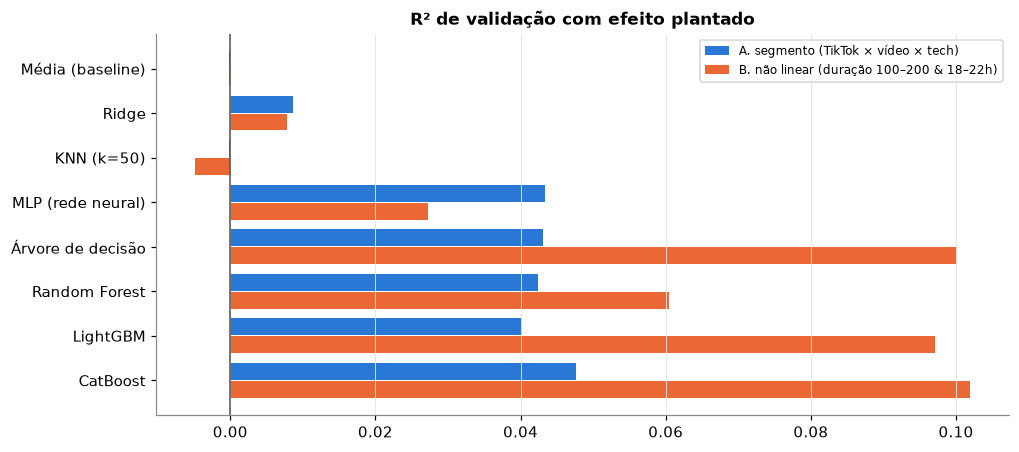

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
r2 = pd.concat({k: v["R² validação"] for k, v in sensitivity.items()}, axis=1).loc[SUBSET[::-1]]
y = np.arange(len(r2))
for i, (col, color) in enumerate(zip(r2.columns, [plots.BLUE, plots.ORANGE])):
    ax.barh(y + (0.2 if i == 0 else -0.2), r2[col], height=0.38, color=color, label=col)
ax.axvline(0, color=plots.INK, linewidth=1)
ax.set_yticks(y, r2.index); ax.set_title("R² de validação com efeito plantado"); ax.legend(fontsize=8); ax.grid(axis="y", visible=False)
plt.show()

**Leitura:**
- **Efeito de segmento (A):** CatBoost, MLP, árvore, Random Forest e LightGBM recuperam o sinal (R² 0,04–0,05, ~1,5% menos erro).
  O Ridge supera o baseline só formalmente (R² 0,009, ~1/5 do sinal), porque o efeito é uma interação de 3 dummies, e um modelo linear sem interações não a representa.
- **Efeito não linear (B):** CatBoost, árvore e LightGBM captam a janela de duração × horário (R² ~0,10, ~4% menos erro). O Random Forest capta parcialmente (0,06), a MLP pouco (0,03) e o Ridge quase nada (0,008).
- **O KNN falha nos dois:** com 30 dimensões, a vizinhança se dilui.
- **Logo, a escolha de modelo importa quando há sinal,** e o protocolo detecta isso sozinho. Nos dados originais, a ausência de ganho é real.

## 5. Previsor final (pronto para uso)

In [8]:
predictor = em.EngagementPredictor.train(df, summary)
print(f"Modelo adotado: {predictor.model_name} · supera baseline: {predictor.beats_baseline} · R² validação: {predictor.cv_r2:.4f}")
examples = pd.DataFrame([
    {"platform": "TikTok", "content_type": "video", "content_category": "tech", "follower_count": 25_000},
    {"platform": "Instagram", "content_type": "image", "content_category": "beauty", "follower_count": 800_000},
    {"platform": "YouTube", "content_type": "video", "content_category": "lifestyle", "follower_count": 5_000},
])
defaults = {c: df[c].astype(str).mode()[0] for c in em.CATEGORICAL} | {c: df[c].median() for c in em.NUMERIC}
examples = pd.DataFrame([defaults | row for row in examples.to_dict("records")])
pd.concat([examples[["platform", "content_type", "content_category", "follower_count"]], predictor.predict(examples)], axis=1)

Modelo adotado: Média (baseline) · supera baseline: False · R² validação: -0.0001


,platform,content_type,content_category,follower_count,engajamento estimado,intervalo 90% inf,intervalo 90% sup,modelo
0,TikTok,video,tech,25000,0.1991,0.1911,0.2071,Média (baseline)
1,Instagram,image,beauty,800000,0.1991,0.1911,0.2071,Média (baseline)
2,YouTube,video,lifestyle,5000,0.1991,0.1911,0.2071,Média (baseline)


In [9]:
# Same training on the data with a planted segment effect: the predictor switches to a real model by itself.
injected = va.inject_engagement_uplift(df, va.demo_segment(df), uplift=0.05)
s_inj, _ = em.compare_models(injected, models=models)
p_inj = em.EngagementPredictor.train(injected, s_inj)
print(f"Com efeito plantado → modelo adotado: {p_inj.model_name} (R² validação {p_inj.cv_r2:.3f})")
pd.concat([examples[["platform", "content_type", "content_category"]], p_inj.predict(examples)], axis=1)

Com efeito plantado → modelo adotado: CatBoost (R² validação 0.048)


,platform,content_type,content_category,engajamento estimado,intervalo 90% inf,intervalo 90% sup,modelo
0,TikTok,video,tech,0.2066,0.1986,0.2148,CatBoost
1,Instagram,image,beauty,0.1991,0.1911,0.2072,CatBoost
2,YouTube,video,lifestyle,0.1991,0.1911,0.2072,CatBoost


**Leitura:** nos dados originais, o previsor adota a **média** (19,9%, intervalo de 90%: 19,1%–20,7%) e avisa que a estimativa é igual para qualquer post. Prometer mais seria vender ruído.
Com sinal plantado, ele troca sozinho para um modelo real, e o post TikTok × vídeo × tech passa a ter previsão maior que os demais.

Para usar: `.venv/bin/python solution/cli/predict_engagement.py --platform TikTok --content_type video --content_category tech --follower_count 25000`

## 6. Conclusões
1. **14 abordagens supervisionadas** (lineares, vizinhos, rede neural, árvores, boosting) e uma formulação de classificação: **nenhuma prevê engajamento melhor que a média**.
2. Modelos flexíveis **decoram ruído** (R² de treino > 0, validação < 0). Sem validação, seriam vendidos como "explica X%".
3. **Mais dados não ajudam** (curva de aprendizado). O que falta são variáveis com relação real com o engajamento.
4. O protocolo é **sensível**: com +5% plantado, o boosting (CatBoost/LightGBM) detecta efeitos de segmento e não lineares. O linear capta só uma fração e o KNN falha. **Com dados reais, a recomendação é o CatBoost/LightGBM**, com adoção automática apenas se superar o baseline.
5. **Entregável:** `EngagementPredictor` + CLI. Ele escolhe sozinho o melhor modelo que supera o baseline, dá intervalo de 90% e cai para a média quando não há sinal.